#    MP MACHINE LEARNING

In [2]:
#Bibliothèques utilisées

from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

import os

## Partie 1
####  Airfoil Self Noise

### Extraction des données

In [ ]:
PROJECT_PATH = r""
#adaptez la variable PROJECT_PATH

In [5]:
df = pd.read_csv("AirfoilSelfNoise.csv")
display(df.head())
df.info()

,f,alpha,c,U_infinity,delta,SSPL
0,800,0.0,0.3048,71.3,0.002663,126.201
1,1000,0.0,0.3048,71.3,0.002663,125.201
2,1250,0.0,0.3048,71.3,0.002663,125.951
3,1600,0.0,0.3048,71.3,0.002663,127.591
4,2000,0.0,0.3048,71.3,0.002663,127.461


<class 'pandas.DataFrame'>
RangeIndex: 1503 entries, 0 to 1502
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   f           1503 non-null   int64  
 1   alpha       1503 non-null   float64
 2   c           1503 non-null   float64
 3   U_infinity  1503 non-null   float64
 4   delta       1503 non-null   float64
 5   SSPL        1503 non-null   float64
dtypes: float64(5), int64(1)
memory usage: 70.6 KB


In [6]:
#Les variables d'entrée
X = df.iloc[:, :-1]
print("Dimensions de X :", X.shape)

#La variable de sortie
Y = df.iloc[:, -1]
print("Dimensions de Y :", Y.shape)

Dimensions de X : (1503, 5)
Dimensions de Y : (1503,)


In [7]:
#Pourcentage d'apprentissage: 80%
ratio = 0.8
split_index = int(len(df) * ratio)
X_train = X.iloc[:split_index]
Y_train = Y.iloc[:split_index]
X_test = X.iloc[split_index:]
Y_test = Y.iloc[split_index:]

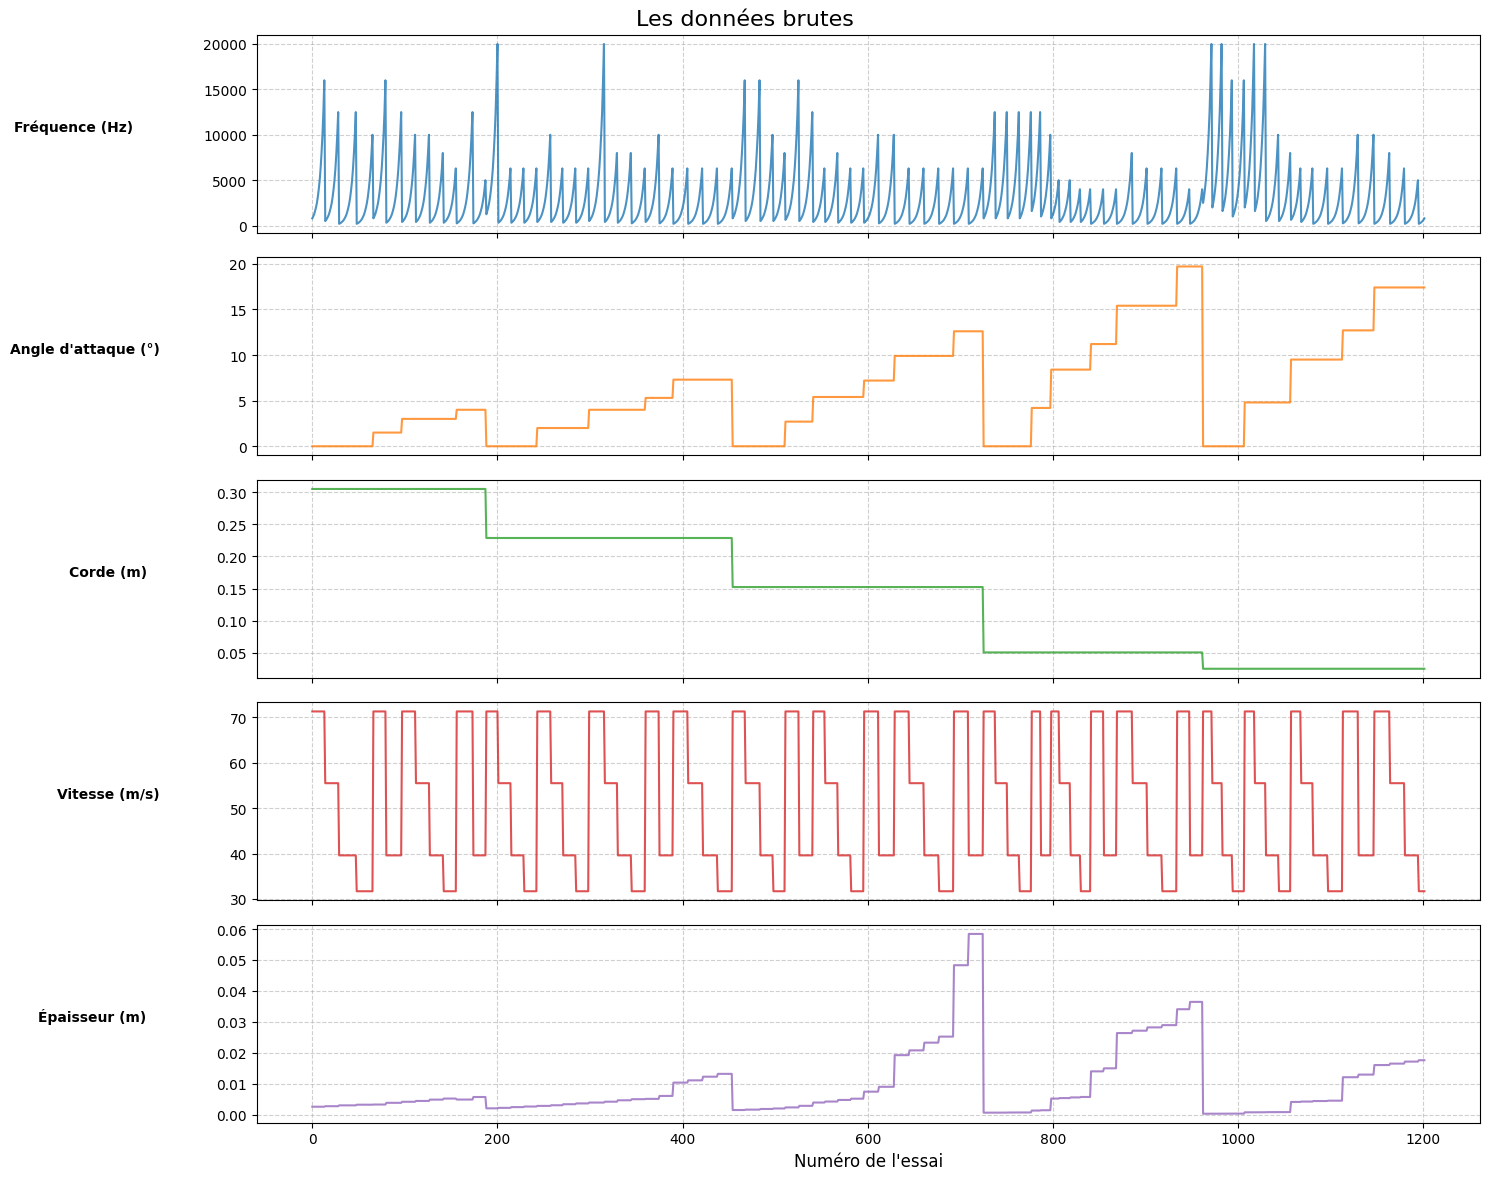

In [8]:
noms_variables = [
    "Fréquence (Hz)",
    "Angle d'attaque (°)",
    "Corde (m)",
    "Vitesse (m/s)",
    "Épaisseur (m)"
]

fig, axes = plt.subplots(nrows=5, ncols=1, figsize=(15, 12), sharex=True)

for i in range(5):
    axes[i].plot(X_train.iloc[:, i].values, color=f'C{i}', linewidth=1.5, alpha=0.8)
    axes[i].set_ylabel(noms_variables[i], fontsize=10, fontweight='bold', rotation=0, labelpad=50, ha='right')
    axes[i].grid(True, linestyle='--', alpha=0.6)

axes[4].set_xlabel("Numéro de l'essai", fontsize=12)
fig.suptitle("Les données brutes", fontsize=16, y=0.98)

plt.tight_layout()
plt.show()

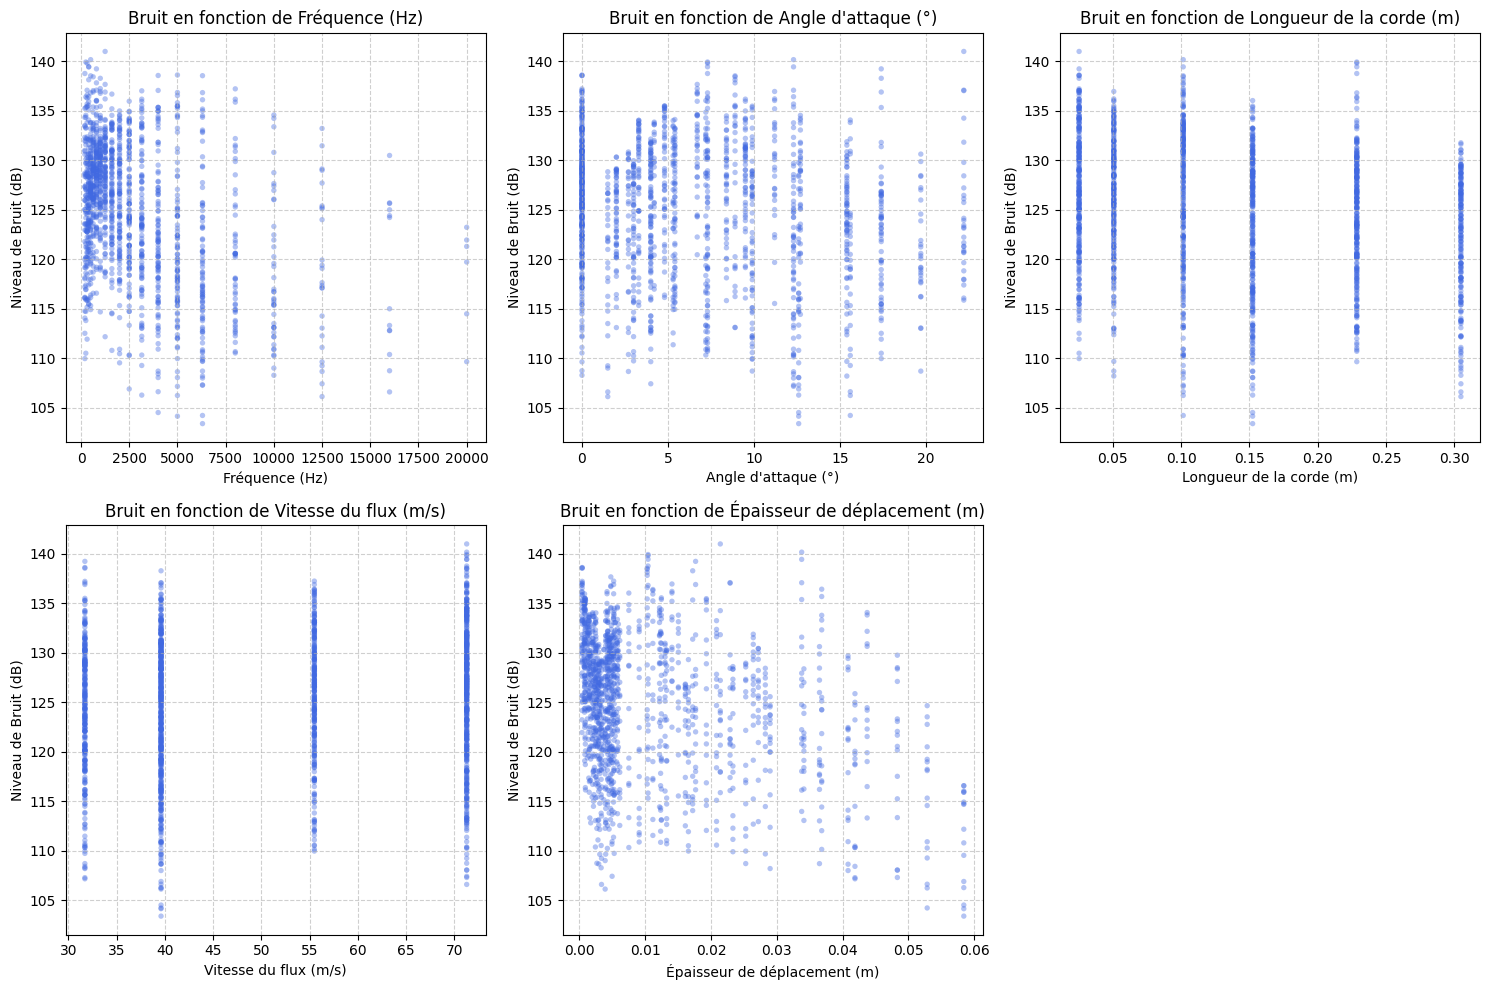

In [9]:
noms_variables = [
    "Fréquence (Hz)",
    "Angle d'attaque (°)",
    "Longueur de la corde (m)",
    "Vitesse du flux (m/s)",
    "Épaisseur de déplacement (m)"
]

fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(15, 10))

axes = axes.flatten()

for i in range(5):
    axes[i].scatter(X.iloc[:, i], Y, alpha=0.4, color='royalblue', edgecolors='none', s=15)

    axes[i].set_title(f"Bruit en fonction de {noms_variables[i]}")
    axes[i].set_xlabel(noms_variables[i])
    axes[i].set_ylabel("Niveau de Bruit (dB)")
    axes[i].grid(True, linestyle='--', alpha=0.6)

fig.delaxes(axes[5])

plt.tight_layout()
plt.show()

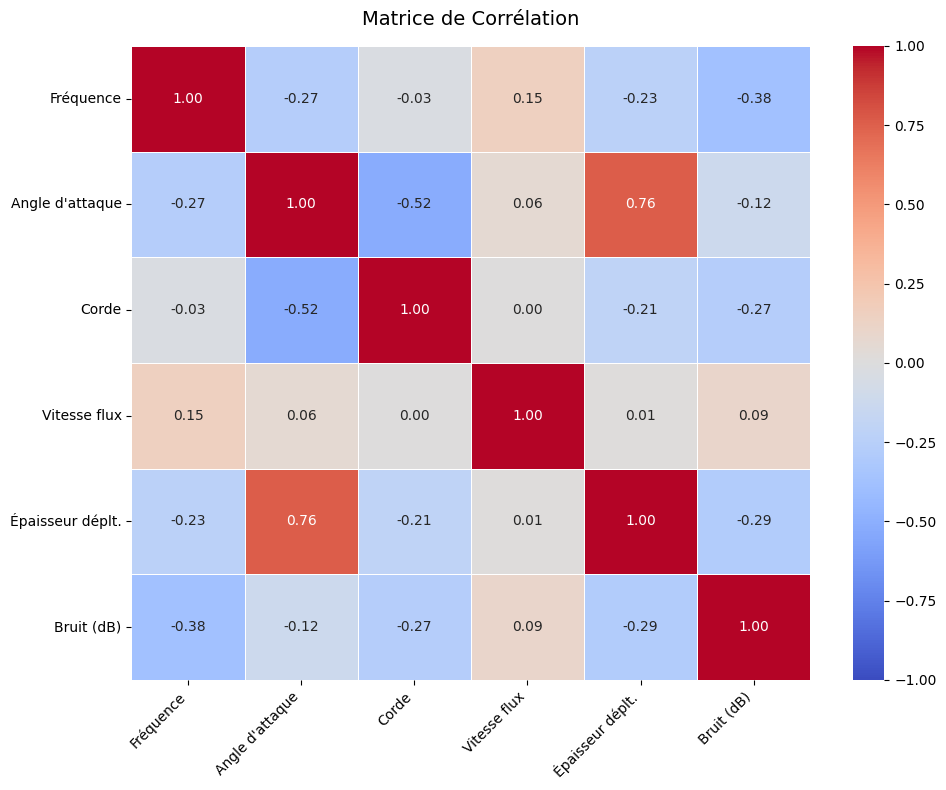

In [11]:
df_aero = X_train.copy()
df_aero.columns = [
    "Fréquence",
    "Angle d'attaque",
    "Corde",
    "Vitesse flux",
    "Épaisseur déplt."
]
df_aero["Bruit (dB)"] = Y
matrice_corr = df_aero.corr()
plt.figure(figsize=(10, 8))

sns.heatmap(matrice_corr, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5, vmin=-1, vmax=1)

plt.title("Matrice de Corrélation", fontsize=14, pad=15)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()

plt.show()

### Visualisation des données

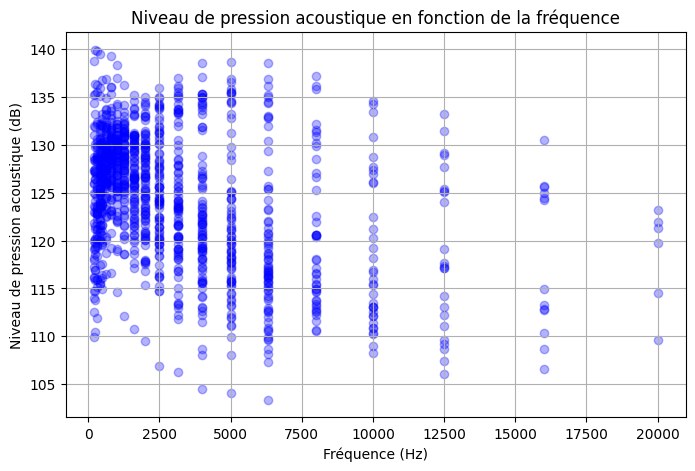

In [12]:
plt.figure(figsize=(8, 5)) # 8 étant la largeur du graph et 5 sa hauteur en pouce
plt.scatter(X_train.iloc[:, 0], Y_train, alpha=0.3, color='blue')
plt.title('Niveau de pression acoustique en fonction de la fréquence')
plt.xlabel('Fréquence (Hz)')
plt.ylabel('Niveau de pression acoustique (dB)')
plt.grid(True)
plt.show()

##### Normalisation

In [13]:
# Normalisationdes données
X_train_mean = X_train.mean() # La moyenne
X_train_std = X_train.std()   # L'écart type

X_train_norm = (X_train - X_train_mean) / X_train_std
X_test_norm = (X_test - X_train_mean) / X_train_std

print("Moyennes après normalisation (proches de 0) :\n", X_train_norm.mean())

#La méthode de normalisation utilisée içi est celle de standarisation (aussi appelée calcul du z-score). La formule est la suivante: X_norm = (X-µ)/sigma avec X la valeur de la colonne avant normalisation, µ la valeur moyenne de toutes les valeurs de cette colonne et sigma l'écart type de toute les valeurs de cette colonne

Moyennes après normalisation (proches de 0) :
 f             7.536955e-17
alpha        -4.729070e-17
c            -9.458140e-17
U_infinity   -6.073899e-16
delta         4.729070e-17
dtype: float64


##### Apprentissage

In [16]:
X_train_mat = X_train_norm.values
X_test_mat = X_test_norm.values
Y_train_mat = Y_train.values.reshape(-1, 1)
y_test_mat = Y_test.values.reshape(-1, 1)

colonne_un_train = np.ones((X_train_mat.shape[0], 1))
colonne_un_test = np.ones((X_test_mat.shape[0], 1))

X_train_final = np.hstack((colonne_un_train, X_train_mat))
X_test_final = np.hstack((colonne_un_test, X_test_mat))

print("Dimensions de la nouvelle matrice X d'apprentissage :",X_train_final.shape)

Dimensions de la nouvelle matrice X d'apprentissage : (1202, 6)


##### Le modèle mathématique adopté est le suivant: y_chapeau = X * theta, avec X la matrice de données et theta le vecteur colonne qui contient les paramètres.

In [17]:
#La fonction côut: Calcule l'erreur du modèle pour un theta donné.
def calculer_cout(X, y, theta):
    n = len(y)
    predictions = X.dot(theta)
    erreurs = predictions - y
    cout = (1 / (2 * n)) * np.sum(erreurs ** 2)
    return cout

In [18]:
def descente_gradient(X, y, theta, alpha, iterations):
    n = len(y)
    historique_cout = np.zeros(iterations)

    for i in range(iterations):
        predictions = X.dot(theta)
        erreurs = predictions - y
        gradient = (1 / n) * X.T.dot(erreurs)
        theta = theta - alpha * gradient # alpha est le taux d'apprentissage
        historique_cout[i] = calculer_cout(X, y, theta)

    return theta, historique_cout

Les paramètres theta appris sont :
 [[124.60019882]
 [ -3.86350484]
 [ -2.24127377]
 [ -3.40765366]
 [  1.38789753]
 [ -1.86331527]]


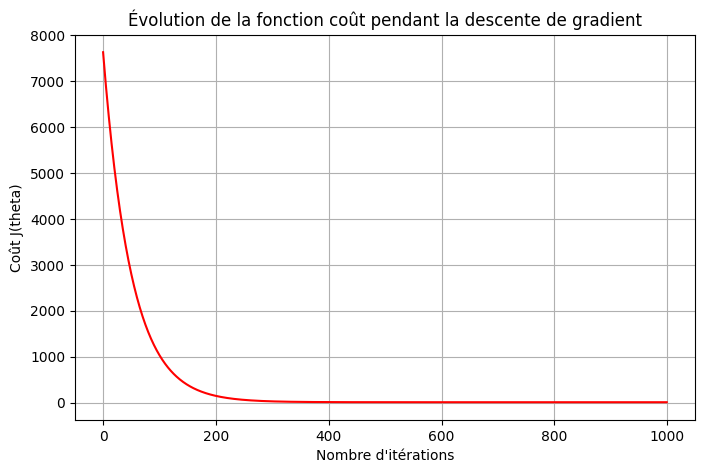

In [19]:
nombre_features = X_train_final.shape[1]
theta_initial = np.zeros((nombre_features, 1))
iterations = 1000 # dépend de alpha, si le taux d'apprentissage est grand on aura besoin de peu d'itérations, s'il est petit en aura besoin de plus
alpha = 0.01 # essayer: 0.001, 0.003, puis 0.01, 0.03, puis 0.1, 0.3.
theta_optimise, historique = descente_gradient(X_train_final, Y_train_mat, theta_initial, alpha, iterations)

print("Les paramètres theta appris sont :\n", theta_optimise)
plt.figure(figsize=(8, 5))
plt.plot(range(iterations), historique, color='red')
plt.title('Évolution de la fonction coût pendant la descente de gradient')
plt.xlabel('Nombre d\'itérations')
plt.ylabel('Coût J(theta)')
plt.grid(True)
plt.show()

##### Si theta est un grand nombre positif, cela signifie que plus la variable augmente, plus le bruit augmente fortement.
##### Si theta est un nombre négatif, cela signifie que plus la variable est longue, plus le bruit diminue.
##### Si theta est très proche de zéro, cela signifie que la variable correspondante ne sert presque à rien pour prédire le bruit.

### Validation analytique

In [20]:
X_T = X_train_final.T  # Transposée de X
theta_analytique = np.linalg.inv(X_T.dot(X_train_final)).dot(X_T).dot(Y_train_mat)

#La formule est comme suit: theta = inverse[(X_T * X)] * X_T * Y

print("Paramètres Theta trouvés par la Descente de Gradient :\n", theta_optimise)
print("\nParamètres Theta trouvés par l'Équation Normale (Exacts) :\n", theta_analytique)

Paramètres Theta trouvés par la Descente de Gradient :
 [[124.60019882]
 [ -3.86350484]
 [ -2.24127377]
 [ -3.40765366]
 [  1.38789753]
 [ -1.86331527]]

Paramètres Theta trouvés par l'Équation Normale (Exacts) :
 [[124.6055782 ]
 [ -3.93228035]
 [ -2.68079804]
 [ -3.60156322]
 [  1.43104822]
 [ -1.53631501]]


##### Les résultats sont quasi-identiques ce qui indique que la DDG a bien convergé.

### Prédictions et évaluations des performances

In [22]:
y_pred_test = X_test_final.dot(theta_optimise)

#Evaluation des performances
n_test = len(y_test_mat)

# MSE (Mean Squared Error)
erreurs = y_test_mat - y_pred_test
mse = (1 / n_test) * np.sum(erreurs ** 2)

# RMSE (Root Mean Squared Error)
rmse = np.sqrt(mse)

# MAE (Mean Absolute Error)
mae = (1 / n_test) * np.sum(np.abs(erreurs))

# R2 (Coefficient de détermination)
y_test_moyenne = np.mean(y_test_mat)
variance_totale = np.sum((y_test_mat - y_test_moyenne) ** 2)
variance_residuelle = np.sum(erreurs ** 2)
r2 = 1 - (variance_residuelle / variance_totale)

print(f"Performances sur l'ensemble de Test :")
print(f"MSE  = {mse:.4f}")
print(f"RMSE = {rmse:.4f} dB (Marge d'erreur moyenne)")
print(f"MAE  = {mae:.4f} dB")
print(f"Score R2 = {r2:.4f} (soit {r2*100:.1f}%)")

Performances sur l'ensemble de Test :
MSE  = 26.3232
RMSE = 5.1306 dB (Marge d'erreur moyenne)
MAE  = 4.0075 dB
Score R2 = 0.5340 (soit 53.4%)


### La régression Ridge

In [23]:
valeurs_lambda = [0, 0.1, 1, 10, 100, 1000]

# Nombre de colonnes de X
n_features = X_train_final.shape[1]
Matrice_I = np.eye(n_features)
Matrice_I[0, 0] = 0

print("Comparaison des scores R2 avec la RR")

for l in valeurs_lambda:
    # np.linalg.inv calcule l'inverse de la matrice
    matrice_a_inverser = X_train_final.T.dot(X_train_final) + l * Matrice_I
    theta_ridge = np.linalg.inv(matrice_a_inverser).dot(X_train_final.T).dot(Y_train_mat)

    y_pred_ridge = X_test_final.dot(theta_ridge)

    erreurs_ridge = y_test_mat - y_pred_ridge
    variance_residuelle_ridge = np.sum(erreurs_ridge ** 2)
    # On a réutilisé la variance_totale calculée précedemment
    r2_ridge = 1 - (variance_residuelle_ridge / variance_totale)

    print(f"Lambda = {l:<6} | Score R2 sur le Test = {r2_ridge:.4f}")

Comparaison des scores R2 avec la RR
Lambda = 0      | Score R2 sur le Test = 0.5322
Lambda = 0.1    | Score R2 sur le Test = 0.5322
Lambda = 1      | Score R2 sur le Test = 0.5322
Lambda = 10     | Score R2 sur le Test = 0.5316
Lambda = 100    | Score R2 sur le Test = 0.5174
Lambda = 1000   | Score R2 sur le Test = 0.3404


##### On remarque que le score baisse pour des différentes valeurs de lambda. En effet pour une valeur dans l'ensemble I = {0; 0.1; 1}, R2 reste stable. Pour des valeurs pluss grandes allant de 10 et 100 jusqu'a 1000, le score s'effond ( + pénalité grande ---> - score R2 ).

##### Interprétation: le modèle initial ne souffrait pas de surapprentissage ( le rôle pricnipale de la RR est de combattre le surapprentissage ). En fait, la RR a rendu le modèle plus mauvais. En forçant une valeur  de lambda très grande, le modèle devient très simple et rigide, se qui nous rammène au sous-apprentissage.

##### Conclusion: Pour ce problème spécifiquement, on a pas besoin d'adopter un modèle complexe, un modèle linéaire simple et standard tel que la DDG ou même l'équation mathématique normale est la meilleure solution.

### Analyse de l'importance des variables

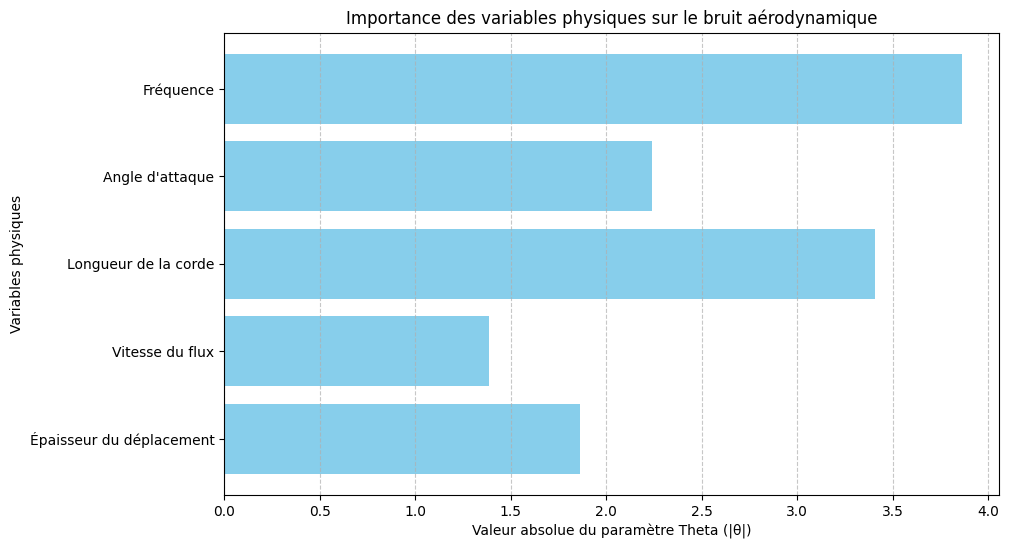

Impact réel des variables (avec le signe) :
- La Fréquence DIMINUE le bruit (Theta = -3.8635)
- La Angle d'attaque DIMINUE le bruit (Theta = -2.2413)
- La Longueur de la corde DIMINUE le bruit (Theta = -3.4077)
- La Vitesse du flux AUGMENTE le bruit (Theta = 1.3879)
- La Épaisseur du déplacement DIMINUE le bruit (Theta = -1.8633)


In [24]:
noms_variables = [
    "Fréquence",
    "Angle d'attaque",
    "Longueur de la corde",
    "Vitesse du flux",
    "Épaisseur du déplacement"
]

# On exclut theta[0] car c'est le biais.
poids_variables = theta_optimise[1:].flatten()

# Le signe indique si le bruit diminue (-) ou augmente (+).
importance_absolue = np.abs(poids_variables)

plt.figure(figsize=(10, 6))
# On utilise barh pour un affichage horizontal
plt.barh(noms_variables, importance_absolue, color='skyblue')

plt.title("Importance des variables physiques sur le bruit aérodynamique")
plt.xlabel("Valeur absolue du paramètre Theta (|θ|)")
plt.ylabel("Variables physiques")
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.gca().invert_yaxis()
plt.show()

print("Impact réel des variables (avec le signe) :")
for nom, poids in zip(noms_variables, poids_variables):
    effet = "AUGMENTE" if poids > 0 else "DIMINUE"
    print(f"- La {nom} {effet} le bruit (Theta = {poids:.4f})")

### Visualisation 3D

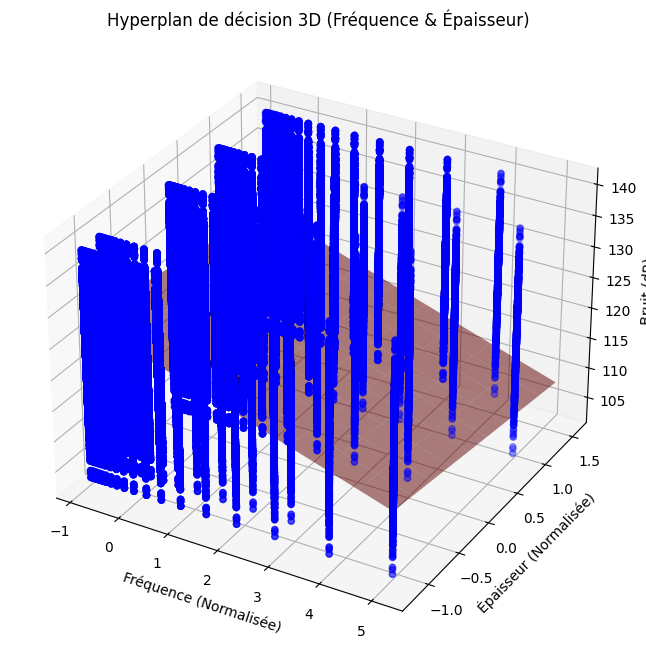

In [25]:
idx_var1 = 0
idx_var2 = 2

X_train_3D = X_train_norm.iloc[:, [idx_var1, idx_var2]].values

# On rajoute la colonne du Biais
X_train_3D_final = np.hstack((np.ones((X_train_3D.shape[0], 1)), X_train_3D))

theta_3D = np.linalg.inv(X_train_3D_final.T.dot(X_train_3D_final)).dot(X_train_3D_final.T).dot(Y_train_mat)


fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(X_train_3D[:, 0], X_train_3D[:, 1], Y_train_mat, color='blue', alpha=0.2, label='Données réelles')

#L''hyperplan
x1_range = np.linspace(X_train_3D[:, 0].min(), X_train_3D[:, 0].max(), 10)
x2_range = np.linspace(X_train_3D[:, 1].min(), X_train_3D[:, 1].max(), 10)
X1, X2 = np.meshgrid(x1_range, x2_range)

# On calcule la prédiction (Z) pour chaque point de cette grille
# Formule : Z = Biais + (Theta1 * X1) + (Theta2 * X2)
Z = theta_3D[0] + theta_3D[1]*X1 + theta_3D[2]*X2

ax.plot_surface(X1, X2, Z, color='red', alpha=0.5)

ax.set_xlabel('Fréquence (Normalisée)')
ax.set_ylabel('Épaisseur (Normalisée)')
ax.set_zlabel('Bruit (dB)')
ax.set_title("Hyperplan de décision 3D (Fréquence & Épaisseur)")
plt.show()

## Partie 2
####  PIMA

### Extraction des données

In [26]:
df_pima = pd.read_csv('PIMA.csv')
print("Les 5 prmières lignes de la base sont:")
display(df_pima.head())
print("Quelques informations sur les colonnes:")
display(df_pima.info())

Les 5 prmières lignes de la base sont:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


Quelques informations sur les colonnes:
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


None

In [27]:
X_pima = df_pima.iloc[:, :-1]
Y_pima = df_pima.iloc[:, -1]
X_train_p, X_test_p, y_train_p, y_test_p = train_test_split(X_pima,Y_pima, test_size=0.2, random_state=42) # Mélanger les patients au hasard (pour éviter d'avoir tous les malades au début et tous les sains à la fin)

print("\nDimensions des données d'apprentissage :", X_train_p.shape)


Dimensions des données d'apprentissage : (614, 8)


### Normalisation

In [28]:
moyenne_p = X_train_p.mean()
ecart_type_p = X_train_p.std()

X_train_p_norm = (X_train_p - moyenne_p) / ecart_type_p
X_test_p_norm = (X_test_p - moyenne_p) / ecart_type_p

X_train_p_final = np.hstack((np.ones((X_train_p_norm.shape[0], 1)), X_train_p_norm))
X_test_p_final = np.hstack((np.ones((X_test_p_norm.shape[0], 1)), X_test_p_norm))

print("Forme finale de X_train_p_final :", X_train_p_final.shape)

Forme finale de X_train_p_final : (614, 9)


### Classification

$$g(z) = \frac{1}{1 + e^{-z}}$$

In [29]:
def sigmoide(z):
    return 1 / (1 + np.exp(-z))
#Transforme n'importe quel nombre (ou matrice) en une valeur entre 0 et 1.
print("\nTest de la sigmoïde pour z=0 :", sigmoide(0))



Test de la sigmoïde pour z=0 : 0.5


$$J(\theta) = -\frac{1}{n} \sum_{i=1}^{n} \left[ y^{(i)} \log(\hat{y}^{(i)}) + (1 - y^{(i)}) \log(1 - \hat{y}^{(i)}) \right]$$

In [30]:
#Calcul du coût pour la régression logistique.
def cout_logistique(X, y, theta):
    n = len(y)
    predictions = sigmoide(X.dot(theta))
    epsilon = 1e-15

    erreur_classe_1 = y * np.log(predictions + epsilon)
    erreur_classe_0 = (1 - y) * np.log(1 - predictions + epsilon)

    cout = -(1 / n) * np.sum(erreur_classe_1 + erreur_classe_0)
    return cout

$$\theta_{nouveau} = \theta_{ancien} - \alpha \times \frac{1}{n} X^T (\hat{y} - y)$$

In [31]:
def descente_gradient_logistique(X, y, theta, alpha, iterations):
    n = len(y)
    historique_cout = np.zeros(iterations)

    y = y.values.reshape(-1, 1) if isinstance(y, pd.Series) else y.reshape(-1, 1)

    for i in range(iterations):
        predictions = sigmoide(X.dot(theta))
        erreurs = predictions - y
        gradient = (1 / n) * X.T.dot(erreurs)
        theta = theta - alpha * gradient
        historique_cout[i] = cout_logistique(X, y, theta)

    return theta, historique_cout

theta_initial_p = np.zeros((X_train_p_final.shape[1], 1))

# Hyperparamètres
iterations_p = 1000
alpha_p = 0.1

theta_opt_logistique, historique_p = descente_gradient_logistique(
    X_train_p_final, y_train_p, theta_initial_p, alpha_p, iterations_p
)

print("Les paramètres theta appris pour le diabète sont :\n", theta_opt_logistique)


Les paramètres theta appris pour le diabète sont :
 [[-0.89186544]
 [ 0.21393247]
 [ 1.09169556]
 [-0.25674888]
 [ 0.04800387]
 [-0.21037446]
 [ 0.79404998]
 [ 0.23392738]
 [ 0.42645185]]


### Visualisation

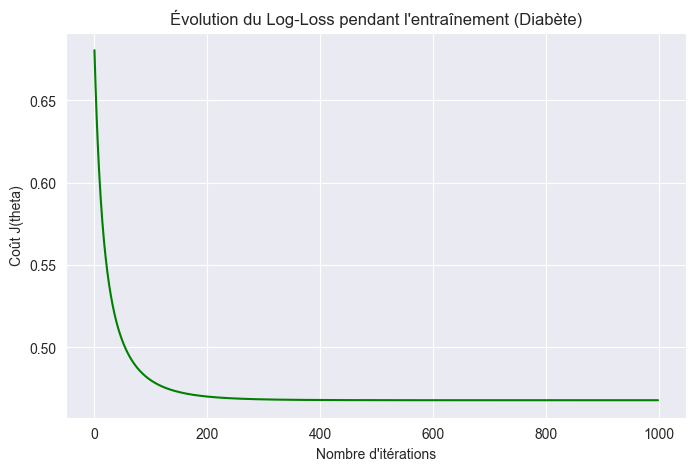

In [32]:
plt.figure(figsize=(8, 5))
plt.plot(range(iterations_p), historique_p, color='green')
plt.title('Évolution du Log-Loss pendant l\'entraînement (Diabète)')
plt.xlabel('Nombre d\'itérations')
plt.ylabel('Coût J(theta)')
plt.grid(True)
plt.show()

Précision globale de notre modèle : 75.32%



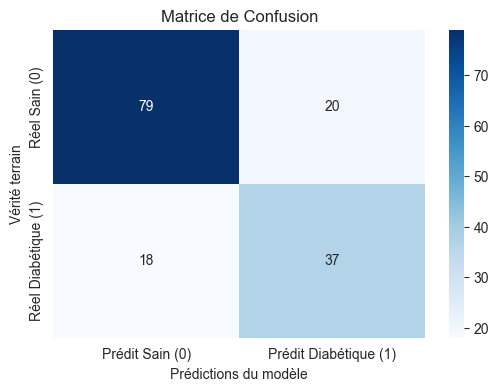

--- Rapport de Classification ---
              precision    recall  f1-score   support

           0       0.81      0.80      0.81        99
           1       0.65      0.67      0.66        55

    accuracy                           0.75       154
   macro avg       0.73      0.74      0.73       154
weighted avg       0.76      0.75      0.75       154



In [33]:
probabilites = sigmoide(X_test_p_final.dot(theta_opt_logistique))

#np.where: Si probabilité >= 0.5, met 1, sinon met 0
y_pred_classes = np.where(probabilites >= 0.5, 1, 0)

#Accuracy
precision = accuracy_score(y_test_p, y_pred_classes)
print(f"Précision globale de notre modèle : {precision * 100:.2f}%\n")

matrice = confusion_matrix(y_test_p, y_pred_classes)

plt.figure(figsize=(6, 4))
sns.heatmap(matrice, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Prédit Sain (0)", "Prédit Diabétique (1)"],
            yticklabels=["Réel Sain (0)", "Réel Diabétique (1)"])
plt.title("Matrice de Confusion")
plt.xlabel("Prédictions du modèle")
plt.ylabel("Vérité terrain")
plt.show()

print("--- Rapport de Classification ---")
print(classification_report(y_test_p, y_pred_classes))

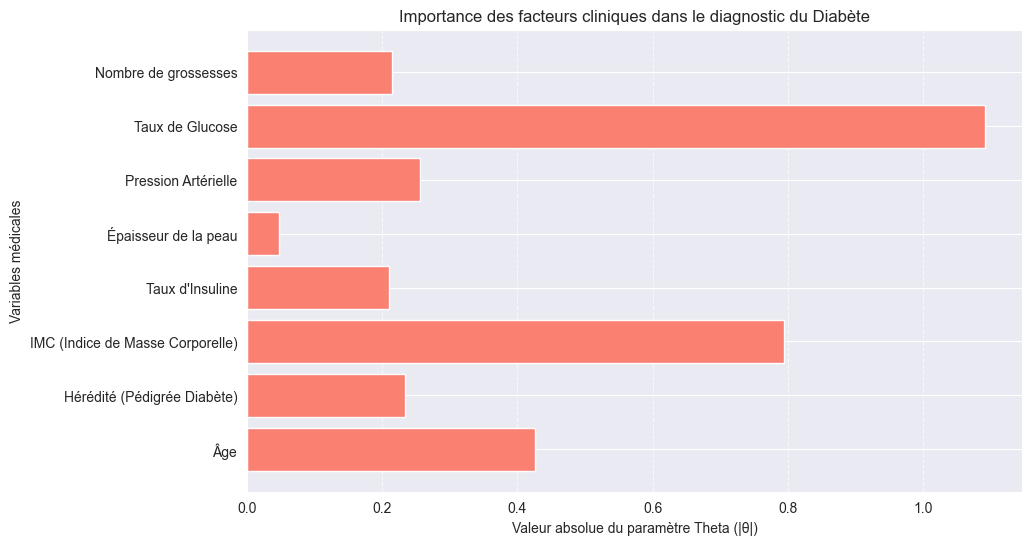

Analyse de l'impact réel (avec le signe) :
- Nombre de grossesses : AUGMENTE le risque (Theta = 0.2139)
- Taux de Glucose : AUGMENTE le risque (Theta = 1.0917)
- Pression Artérielle : DIMINUE le risque (Theta = -0.2567)
- Épaisseur de la peau : AUGMENTE le risque (Theta = 0.0480)
- Taux d'Insuline : DIMINUE le risque (Theta = -0.2104)
- IMC (Indice de Masse Corporelle) : AUGMENTE le risque (Theta = 0.7940)
- Hérédité (Pédigrée Diabète) : AUGMENTE le risque (Theta = 0.2339)
- Âge : AUGMENTE le risque (Theta = 0.4265)


In [35]:
noms_variables_med = [
    "Nombre de grossesses",
    "Taux de Glucose",
    "Pression Artérielle",
    "Épaisseur de la peau",
    "Taux d'Insuline",
    "IMC (Indice de Masse Corporelle)",
    "Hérédité (Pédigrée Diabète)",
    "Âge"
]

poids_variables_med = theta_opt_logistique[1:].flatten()

importance_absolue_med = np.abs(poids_variables_med)

plt.figure(figsize=(10, 6))
plt.barh(noms_variables_med, importance_absolue_med, color='salmon')

plt.title("Importance des facteurs cliniques dans le diagnostic du Diabète")
plt.xlabel("Valeur absolue du paramètre Theta (|θ|)")
plt.ylabel("Variables médicales")
plt.grid(axis='x', linestyle='--', alpha=0.7)

plt.gca().invert_yaxis()
plt.show()

print("Analyse de l'impact réel (avec le signe) :")
for nom, poids in zip(noms_variables_med, poids_variables_med):
    effet = "AUGMENTE" if poids > 0 else "DIMINUE"
    print(f"- {nom} : {effet} le risque (Theta = {poids:.4f})")